# Notebook 02: Chuẩn hóa Snapshot & Khởi tạo Trạng thái Kho (Phase 2)

**Nghiên cứu:** Tái hiện bài báo *Agentic Architecture for Progressive Autonomous Storage Location Assignment in Warehouses* (Rodrigo Furlan de Assis et al., 2026).

Notebook này trực quan hóa toàn diện kết quả **Giai đoạn 2**:
1. Chuẩn hóa snapshot `Random_Storage.csv` sang dạng bảng dài (Long format) và lưu vào `data/interim/`.
2. Kiểm tra sức chứa $C_l = 18$ ô cho mỗi vị trí và phân tích tồn kho.
3. Giải phóng khoảng 20% dung lượng kho bằng `seed=42` để đón hàng nhập.
4. Trực quan hóa bản đồ nhiệt (2D Heatmap) không gian kho trước và sau giải phóng.
5. So sánh phân phối Mixing Index giữa `Paper-like Baseline MI` (trước giải phóng) và `Initial Simulation MI` (sau giải phóng).


In [1]:
import os
import sys
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 120

sys.path.append('..')
from src.model.warehouse_state import WarehouseState

print("Phase 2 environment loaded successfully.")


Phase 2 environment loaded successfully.


## 1. Dữ liệu Snapshot Chuẩn hóa (Long Format) trong `data/interim/`

In [2]:
df_long_z34 = pd.read_csv('../data/interim/random_storage_long_z34.csv')
print(f"Tổng số ô trong phạm vi chính z in [3, 4]: {len(df_long_z34):,}")
print(f"Số vị trí: {df_long_z34['originalLocation'].nunique()}")
print(f"Số SKU: {df_long_z34['Reference'].nunique()}")
print(f"Dải kích cỡ: [{df_long_z34['size'].min()}, {df_long_z34['size'].max()}]")
display(df_long_z34.head(6))


Tổng số ô trong phạm vi chính z in [3, 4]: 10,800
Số vị trí: 600
Số SKU: 208
Dải kích cỡ: [4.0, 16.0]


,originalLocation,slot_id,Reference,size,x,y,z
0,A-14-30,1,A7MDBC,4.0,352,0,3
1,A-14-30,2,4ILN0A,6.0,352,0,3
2,A-14-30,3,IA7X1P,6.0,352,0,3
3,A-14-30,4,RN2DSQ,15.0,352,0,3
4,A-14-30,5,PZUF7K,12.0,352,0,3
5,A-14-30,6,TAHFOD,10.0,352,0,3


## 2. Giải phóng ~20% Dung lượng Kho với Seed=42

,scope_name,locations_count,capacity_per_location,total_warehouse_capacity,occupied_units_before,free_capacity_before,occupancy_rate_before_pct,baseline_mi_before,critical_locations_before_pct,released_units_count,actual_release_pct,occupied_units_after,free_capacity_after,occupancy_rate_after_pct,initial_mi_after_release,critical_locations_after_pct,delta_mi_due_to_release
0,"Candidate Scope (z in {3, 4})",600,18,10800,10800,0,100.0,0.9136,99.83,2160,20.00,8640,2160,80.00,0.9015,98.83,-0.0121
1,Sensitivity Scope (z=3),301,18,5418,5418,0,100.0,0.9131,99.67,1084,20.01,4334,1084,79.99,0.9013,99.34,-0.0117
2,Sensitivity Scope (z=4),299,18,5382,5382,0,100.0,0.9142,100.00,1076,19.99,4306,1076,80.01,0.9046,99.67,-0.0096
3,Full Warehouse (z in {1..4}),2292,18,41256,41256,0,100.0,0.4362,47.69,8251,20.00,33005,8251,80.00,0.4300,47.60,-0.0062


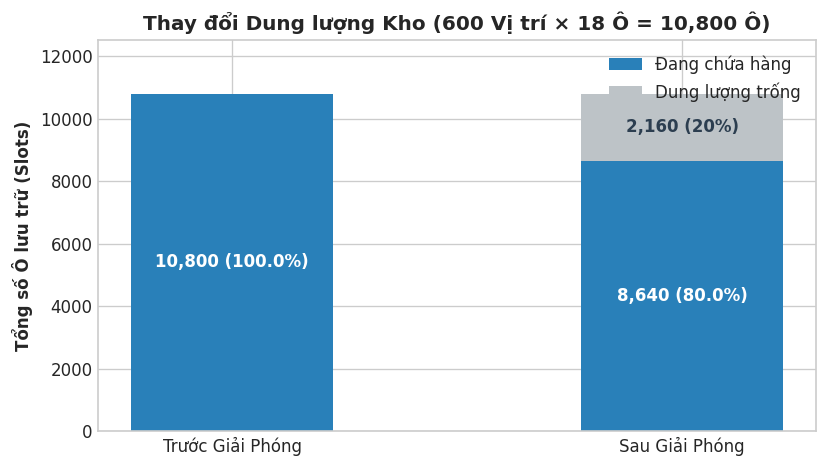

In [3]:
df_summary = pd.read_csv('../outputs/tables/snapshot_mi_before_after_release.csv')
display(df_summary)

z34_row = df_summary[df_summary['scope_name'].str.contains('z in {3, 4}')].iloc[0]

fig, ax = plt.subplots(figsize=(7, 4))
labels = ['Trước Giải Phóng', 'Sau Giải Phóng']
occupied = [z34_row['occupied_units_before'], z34_row['occupied_units_after']]
free = [z34_row['free_capacity_before'], z34_row['free_capacity_after']]

p1 = ax.bar(labels, occupied, width=0.45, label='Đang chứa hàng', color='#2980B9')
p2 = ax.bar(labels, free, width=0.45, bottom=occupied, label='Dung lượng trống', color='#BDC3C7')

ax.set_ylabel('Tổng số Ô lưu trữ (Slots)', fontweight='bold')
ax.set_title(f"Thay đổi Dung lượng Kho ({z34_row['locations_count']} Vị trí × 18 Ô = {z34_row['total_warehouse_capacity']:,} Ô)", fontweight='bold', fontsize=12)
ax.set_ylim(0, 12500)
ax.legend(loc='upper right')

for p in p1:
    h = p.get_height()
    ax.text(p.get_x() + p.get_width()/2., h/2., f"{int(h):,} ({h/10800*100:.1f}%)", ha='center', va='center', color='white', fontweight='bold')

ax.text(p2[1].get_x() + p2[1].get_width()/2., occupied[1] + free[1]/2., f"{int(free[1]):,} (20%)", ha='center', va='center', color='#2C3E50', fontweight='bold')

plt.tight_layout()
plt.show()


## 3. Phân tích Phân phối Mixing Index: Trước vs. Sau Giải phóng

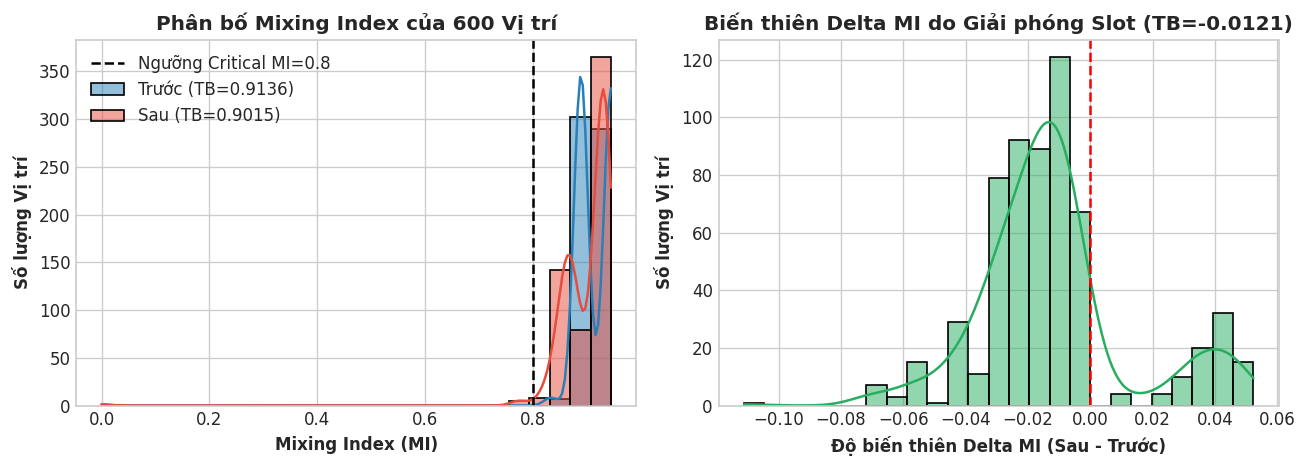

In [4]:
df_comp = pd.read_csv('../outputs/tables/location_level_mi_z34.csv')

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))

sns.histplot(df_comp['mi_before'], bins=25, kde=True, color='#2980B9', ax=ax1, label=f"Trước (TB={df_comp['mi_before'].mean():.4f})", alpha=0.5)
sns.histplot(df_comp['mi_after'], bins=25, kde=True, color='#E74C3C', ax=ax1, label=f"Sau (TB={df_comp['mi_after'].mean():.4f})", alpha=0.5)
ax1.axvline(0.8, color='black', linestyle='--', label='Ngưỡng Critical MI=0.8')
ax1.set_xlabel('Mixing Index (MI)', fontweight='bold')
ax1.set_ylabel('Số lượng Vị trí', fontweight='bold')
ax1.set_title('Phân bố Mixing Index của 600 Vị trí', fontweight='bold')
ax1.legend()

sns.histplot(df_comp['delta_mi'], bins=25, kde=True, color='#27AE60', ax=ax2)
ax2.axvline(0.0, color='red', linestyle='--')
ax2.set_xlabel('Độ biến thiên Delta MI (Sau - Trước)', fontweight='bold')
ax2.set_ylabel('Số lượng Vị trí', fontweight='bold')
ax2.set_title(f"Biến thiên Delta MI do Giải phóng Slot (TB={df_comp['delta_mi'].mean():.4f})", fontweight='bold')

plt.tight_layout()
plt.show()


## 4. Bản đồ Nhiệt Không gian 2D (Spatial Heatmap) của Mixing Index

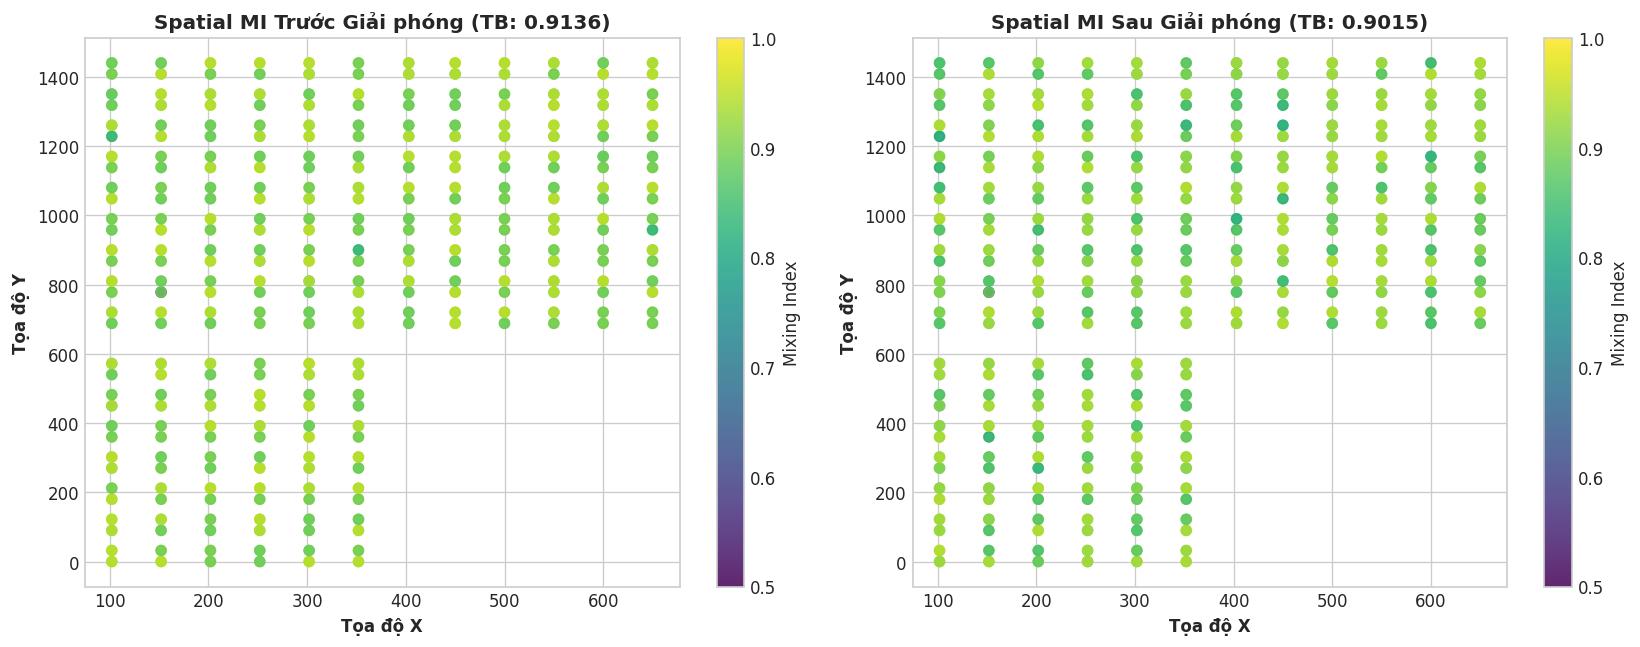

In [5]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5))

scatter1 = ax1.scatter(df_comp['x'], df_comp['y'], c=df_comp['mi_before'], cmap='viridis', s=35, vmin=0.5, vmax=1.0, alpha=0.85)
fig.colorbar(scatter1, ax=ax1, label='Mixing Index')
ax1.set_title(f"Spatial MI Trước Giải phóng (TB: {df_comp['mi_before'].mean():.4f})", fontweight='bold')
ax1.set_xlabel('Tọa độ X', fontweight='bold')
ax1.set_ylabel('Tọa độ Y', fontweight='bold')

scatter2 = ax2.scatter(df_comp['x'], df_comp['y'], c=df_comp['mi_after'], cmap='viridis', s=35, vmin=0.5, vmax=1.0, alpha=0.85)
fig.colorbar(scatter2, ax=ax2, label='Mixing Index')
ax2.set_title(f"Spatial MI Sau Giải phóng (TB: {df_comp['mi_after'].mean():.4f})", fontweight='bold')
ax2.set_xlabel('Tọa độ X', fontweight='bold')
ax2.set_ylabel('Tọa độ Y', fontweight='bold')

plt.tight_layout()
plt.show()


## 5. Tệp Vết Giải phóng Slot (`released_slots_z34_seed42.csv`)

In [6]:
df_released = pd.read_csv('../data/processed/released_slots_z34_seed42.csv')
print(f"Tổng số slot được giải phóng: {len(df_released):,} ô")
print(f"Số vị trí có ô được giải phóng: {df_released['originalLocation'].nunique()} / 600 vị trí")
display(df_released.head(10))


Tổng số slot được giải phóng: 2,160 ô
Số vị trí có ô được giải phóng: 585 / 600 vị trí


,originalLocation,slot_id,Reference,size,seed,release_ratio
0,Q-17-30,4,HA0BOB,12.0,42,0.2
1,M-19-30,6,H1I7JZ,12.0,42,0.2
2,K-23-40,11,4E0KXI,10.0,42,0.2
3,I-22-30,12,WRRW1W,7.0,42,0.2
4,J-09-40,5,YKQY4X,11.0,42,0.2
5,L-17-30,9,8E9F1P,14.0,42,0.2
6,J-24-40,11,3LQL9L,14.0,42,0.2
7,Q-07-40,18,UMKYTJ,10.0,42,0.2
8,H-04-30,15,ETU70R,11.0,42,0.2
9,H-06-40,13,DSQXYR,5.0,42,0.2
